# Лабораторная работа № 3 Романов Михаил ПМИ-3

**Вариант 6.** Тема: страны население, регион, экономические показатели.

In [1]:
import json
import math
import os
import random
import time
import unicodedata
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests


def _find_lab_dir() -> Path:
    '''Каталог лабораторной: ищем task_3lab.md в текущем каталоге или в 3lab/.'''
    here = Path.cwd()
    if (here / "task_3lab.md").exists():
        return here
    for child in ("3lab", "."):
        candidate = here / child
        if (candidate / "task_3lab.md").exists():
            return candidate.resolve()
    return here


LAB_DIR = _find_lab_dir()
NOCODE_DIR = LAB_DIR / "nocode"
FIG_DIR = LAB_DIR / "figures"
NOCODE_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

RAW_PATH = LAB_DIR / "data_raw.jsonl"
CLEAN_PATH = LAB_DIR / "data_clean.csv"
COUNTRIES_PATH = LAB_DIR / "data_countries.csv"
LOG_PATH = LAB_DIR / "collection_log.csv"
STATE_PATH = LAB_DIR / "state.json"
REJECTS_PATH = LAB_DIR / "rejects.jsonl"

try:  # секреты — только из окружения (.env в корне репозитория)
    from dotenv import load_dotenv

    load_dotenv(LAB_DIR.parent / ".env")
except Exception:
    pass


def mask_secret(value: str) -> str:
    '''Маскирование секрета для вывода в блокнот/отчёт.'''
    if not value:
        return "(не задан)"
    return value[:2] + "*" * max(0, len(value) - 4) + value[-2:]


PARSER_VERSION = "3lab-v6/1.0"
UA = "StudentScraperBot/1.0 (+https://github.com/PINNOS/parsing)"
TIMEOUT = 20

JSONPLACEHOLDER = "https://jsonplaceholder.typicode.com"
COUNTRIESNOW = "https://countriesnow.space/api/v0.1"
WORLDBANK = "https://api.worldbank.org/v2"

TARGET_RECORDS = 500
PAGE_SIZE = 100
MAX_PAGES = 8
RATE_PER_SECOND = 4.0

print("Каталог лабораторной:", LAB_DIR)
print("DEMO_API_KEY (маскировано):", mask_secret(os.getenv("DEMO_API_KEY", "")))
print("Все три API публичные, регистрация и ключи не требуются.")

Каталог лабораторной: Z:\Work\ED\4trim\parsing\3lab
DEMO_API_KEY (маскировано): (не задан)
Все три API публичные, регистрация и ключи не требуются.


## 1. Паспорт API

### 1.1. JSONPlaceholder — основной ресурс `/comments`

| Поле | Значение |
|---|---|
| Название и базовый URL | JSONPlaceholder, `https://jsonplaceholder.typicode.com` |
| Версия и способ её указания | версионирования нет (стабильный тестовый сервис) |
| Используемые эндпоинты | `GET /comments`, `GET /posts`, `GET /users` |
| Аутентификация | не требуется |
| Тип пагинации и параметры | offset/limit: `_page`, `_limit`; всего записей — заголовок `X-Total-Count` |
| Документированные лимиты | не документированы; сервис тренировочный |
| Заголовки лимитов в ответе | `X-Total-Count` (общее число записей) |
| Формат дат | дат нет |
| Ключ уникальности записи | `id` комментария (целое) |
| Наличие персональных данных | псевдо-ПДн: имя автора и e-mail → маскируются при выгрузке |
| Ограничения условий использования | публичный тестовый сервис для демонстраций |

### 1.2. countriesnow.space — справочник стран (замена REST Countries)

| Поле | Значение |
|---|---|
| Название и базовый URL | CountriesNow, `https://countriesnow.space/api/v0.1` |
| Используемые эндпоинты | `POST/GET /countries/positions`, `POST/GET /countries/population` |
| Аутентификация | не требуется |
| Тип пагинации | нет; отдаёт полный справочник |
| Формат дат | годы в поле `year` (число) |
| Ключ уникальности записи | `iso2` / `iso3` страны |
| ПДн | нет |
| Ограничения | публичный справочник, указание источника рекомендуется |

### 1.3. World Bank API — экономические показатели

| Поле | Значение |
|---|---|
| Название и базовый URL | World Bank Open Data, `https://api.worldbank.org/v2` |
| Версия и способ указания | v2 в пути (`/v2/...`) |
| Используемые эндпоинты | `GET /country`, `GET /country/all/indicator/{code}` |
| Аутентификация | не требуется |
| Тип пагинации и параметры | offset/limit: `per_page`, `page`; метаданные `page`, `pages`, `total` |
| Документированные лимиты | мягкие, ограничений по частоте нет; не более 400 записей на страницу |
| Заголовки лимитов в ответе | нет (лимиты описаны в метаданных ответа) |
| Формат дат | `date` — год (строка `YYYY`) |
| Ключ уникальности записи | `countryiso3code` + `indicator.id` + `date` |
| ПДн | нет |
| Ограничения условий использования | обязательна ссылка на источник данных; данные под CC BY 4.0 |

**Коды состояния и решения (для обработчика повторов):**

| Код | Класс | Действие пайплайна |
|---|---|---|
| 200 | успех | принять данные |
| 304 | успех (кэш) | использовать локальную копию (задание +10, ETag) |
| 400 / 404 | постоянная ошибка клиента | **не повторять**, записать в журнал |
| 401 / 403 | нет доступа / блокировка | **не повторять**, остановить источник, зафиксировать инцидент |
| 429 | превышен лимит | повторять, уважать `Retry-After`, backoff с джиттером |
| 500 / 502 / 503 / 504 | временная ошибка сервера | повторять с экспоненциальной задержкой |

In [2]:
class ApiError(RuntimeError):
    '''Ошибка обращения к API: неожидаемый HTTP-статус или Content-Type.'''


def create_session() -> requests.Session:
    '''Сессия с обязательным User-Agent и Accept; таймаут задаётся в каждом запросе.'''
    session = requests.Session()
    session.headers.update(
        {
            "User-Agent": UA,
            "Accept": "application/json",
            "Accept-Language": "ru,en;q=0.8",
        }
    )
    return session


def get_json(resp, source: str):
    '''Защитный разбор ответа: проверка статуса и Content-Type, первые 200 байт тела при ошибке.'''
    ctype = resp.headers.get("Content-Type", "")
    if resp.status_code != 200:
        raise ApiError(f"{source}: HTTP {resp.status_code} для {resp.url} :: {resp.text[:200]!r}")
    if "json" not in ctype.lower():
        raise ApiError(f"{source}: ожидался JSON, получен {ctype!r} :: {resp.text[:200]!r}")
    return resp.json()

### 1.4. пробные запросы

In [3]:
probe_session = create_session()

print("--- JSONPlaceholder /comments (страница 1, 2 записи) ---")
r = probe_session.get(f"{JSONPLACEHOLDER}/comments", params={"_page": 1, "_limit": 2}, timeout=TIMEOUT)
print("status:", r.status_code, "| Content-Type:", r.headers.get("Content-Type"))
print("X-Total-Count:", r.headers.get("X-Total-Count"))
sample = get_json(r, "jsonplaceholder.comments")[0]
print("поля записи:", list(sample.keys()), "| ключ уникальности: id")

print("\n--- countriesnow.space /countries/positions ---")
r = probe_session.get(f"{COUNTRIESNOW}/countries/positions", timeout=TIMEOUT)
positions_probe = get_json(r, "countriesnow.positions")["data"]
print("status:", r.status_code, "| стран:", len(positions_probe), "| поля:", list(positions_probe[0].keys()))

print("\n--- countriesnow.space /countries/population (структура с вложенным массивом) ---")
r = probe_session.get(f"{COUNTRIESNOW}/countries/population", timeout=TIMEOUT)
population_probe = get_json(r, "countriesnow.population")["data"]
print("status:", r.status_code, "| стран:", len(population_probe), "| поля:", list(population_probe[0].keys()))
print("вложенный массив:", "{country, code, iso3, populationCounts:[{year, value}]}")

print("\n--- World Bank /country (метаданные и пагинация) ---")
r = probe_session.get(f"{WORLDBANK}/country", params={"format": "json", "per_page": 3, "page": 1}, timeout=TIMEOUT)
meta, rows = get_json(r, "worldbank.country")
print("meta:", {k: meta[k] for k in ("page", "pages", "per_page", "total")})
print("поля страны:", list(rows[0].keys()))

print("\n--- World Bank indicator (проверка формата наблюдения) ---")
r = probe_session.get(
    f"{WORLDBANK}/country/all/indicator/NY.GDP.PCAP.CD",
    params={"format": "json", "per_page": 2, "page": 1, "date": "2022"},
    timeout=TIMEOUT,
)
meta, rows = get_json(r, "worldbank.indicator")
print("meta:", {k: meta[k] for k in ("page", "pages", "total")}, "| ключ: countryiso3code+date")
print("пример:", {k: rows[0][k] for k in ("countryiso3code", "date", "value")})

--- JSONPlaceholder /comments (страница 1, 2 записи) ---


status: 200 | Content-Type: application/json; charset=utf-8
X-Total-Count: 500
поля записи: ['postId', 'id', 'name', 'email', 'body'] | ключ уникальности: id

--- countriesnow.space /countries/positions ---


status: 200 | стран: 242 | поля: ['name', 'iso2', 'long', 'lat']

--- countriesnow.space /countries/population (структура с вложенным массивом) ---


status: 200 | стран: 263 | поля: ['country', 'code', 'iso3', 'populationCounts']
вложенный массив: {country, code, iso3, populationCounts:[{year, value}]}

--- World Bank /country (метаданные и пагинация) ---


meta: {'page': 1, 'pages': 99, 'per_page': '3', 'total': 296}
поля страны: ['id', 'iso2Code', 'name', 'region', 'adminregion', 'incomeLevel', 'lendingType', 'capitalCity', 'longitude', 'latitude']

--- World Bank indicator (проверка формата наблюдения) ---
meta: {'page': 1, 'pages': 133, 'total': 266} | ключ: countryiso3code+date
пример: {'countryiso3code': 'AFE', 'date': '2022', 'value': 1675.90252377611}


пробные запросы. Все три источника ответили `200` и отдали JSON, диагностика контракта пройдена без сюрпризов

## 2. Ограничение скорости, повторы и журнал

**Ограничитель скорости.** Класс `RateLimiter` token bucket. не более `rate` запросов в секунду, всплеск `burst`, случайная пауза-джиттер 25 % (снижает одновременность при параллельных запусках).

**Повторы.** Повторяем только 429 и 5xx (расширяемый список), с экспоненциальной задержкой и full jitter, с учётом число или дата-формат `Retry-After`. Для 4xx повторы запрещены. ошибка клиента не исчезнет при повторе.

**Журнал.** Каждая попытка каждого запроса пишется в REQUEST_LOG со статусом, длительностью и номером попытки; итог сохраняется в collection_log.csv.

In [ ]:
class RateLimiter:

    def __init__(self, rate: float = 4.0, burst: int = 4, jitter: float = 0.25):
        self.rate = float(rate)
        self.burst = int(burst)
        self.jitter = float(jitter)
        self.tokens = float(burst)
        self.updated = time.monotonic()
        self.waits = []

    def wait(self) -> None:
        while True:
            now = time.monotonic()
            self.tokens = min(self.burst, self.tokens + (now - self.updated) * self.rate)
            self.updated = now
            if self.tokens >= 1.0:
                self.tokens -= 1.0
                pause = random.uniform(0.0, self.jitter) / self.rate if self.jitter else 0.0
                if pause:
                    time.sleep(pause)
                    self.waits.append(pause)
                return
            time.sleep((1.0 - self.tokens) / self.rate)


def backoff_delays(attempts: int = 6, base: float = 0.5, cap: float = 15.0, jitter: bool = True):
    # Экспоненциальная задержка jitter=True полный джиттер (случайная доля интервала)
    delays = []
    for i in range(attempts):
        raw = min(cap, base * (2**i))
        delays.append(random.uniform(0, raw) if jitter else raw)
    return delays


def parse_retry_after(value):
    # Парсит заголовок Retry-After: число секунд или HTTP-дата (RFC 7231).
    if not value:
        return None
    value = value.strip()
    if value.isdigit():
        return float(value)
    try:
        from email.utils import parsedate_to_datetime

        parsed = parsedate_to_datetime(value)
        if parsed.tzinfo is None:
            parsed = parsed.replace(tzinfo=timezone.utc)
        return max(0.0, (parsed - datetime.now(timezone.utc)).total_seconds())
    except Exception:
        return None


RETRY_STATUSES = {429, 500, 502, 503, 504}
REQUEST_LOG = []


def request_with_retry(session, url, *, params=None, source="", page=None, max_attempts=4, limiter=None):
    # GET с лимитером, повторами только для 429/5xx, backoff+jitter и уважением Retry-After
    last_error = None
    for attempt in range(1, max_attempts + 1):
        if limiter is not None:
            limiter.wait()
        started = time.perf_counter()
        try:
            resp = session.get(url, params=params, timeout=TIMEOUT)
        except requests.RequestException as exc:
            resp, last_error = None, exc
        elapsed = time.perf_counter() - started

        status = resp.status_code if resp is not None else None
        retry_after = parse_retry_after(resp.headers.get("Retry-After")) if resp is not None else None
        REQUEST_LOG.append(
            {
                "timestamp": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                "source": source,
                "page": page,
                "url": url,
                "params": json.dumps(params or {}, ensure_ascii=False),
                "status": status,
                "attempt": attempt,
                "duration_ms": round(elapsed * 1000, 1),
                "records": None,
                "retry_after_s": retry_after,
                "error": None if resp is not None else type(last_error).__name__,
            }
        )

        if resp is not None and resp.status_code == 200:
            return resp

        transient = resp is None or resp.status_code in RETRY_STATUSES
        if not transient or attempt == max_attempts:
            if resp is not None:
                raise ApiError(f"{source}: HTTP {status} для {url} params={params} :: {resp.text[:200]!r}")
            raise ApiError(f"{source}: сетевая ошибка для {url} :: {last_error}")

        delay = backoff_delays(max_attempts, base=0.5, cap=15.0)[attempt - 1]
        if retry_after is not None:
            delay = max(delay, retry_after)
        time.sleep(delay)
    raise ApiError(f"{source}: исчерпаны попытки для {url}")


pd.DataFrame(
    [
        {"попытка": i + 1, "задержка, с": round(d, 3)}
        for i, d in enumerate(backoff_delays(attempts=6, base=0.5, cap=15.0, jitter=True))
    ]
)

,попытка,"задержка, с"
0,1,0.433
1,2,0.671
2,3,1.479
3,4,3.852
4,5,3.324
5,6,0.500


задержки растут экспоненциально (0,5 → 1 → 2 → 4 → 8 с, с потолком 15 с), но благодаря полному джиттеру каждая конкретная задержка случайна в диапазоне [0, base·2^n]. Смысл не ждать ровно 8 секунд, а рассинхронизировать повторы, чтобы несколько запусков пайплайна не ударили в API одновременно. Повторы применяются только к 429/5xx: для 4xx они бессмысленны и потому запрещены

### 2.0. Живая проверка политики повторов

Проверяем на нейтральном HTTP-тест-сервисе httpbin.org: **503 повторяется** (временная ошибка сервера), **404 не повторяется** (постоянная ошибка клиента). Демонстрационные попытки исключаются из рабочего журнала сбора. Дополнительно проверяется разбор Retry-After в обоих форматах.

In [5]:
HTTPBIN = "https://httpbin.org"
demo_limiter = RateLimiter(rate=2.0, burst=2, jitter=0.2)

start_log = len(REQUEST_LOG)
try:
    request_with_retry(probe_session, f"{HTTPBIN}/status/503", source="httpbin.503", max_attempts=3, limiter=demo_limiter)
except ApiError as exc:
    print("503 -> ApiError (ожидаемо):", str(exc)[:100])
attempts_503 = len(REQUEST_LOG) - start_log

start_log = len(REQUEST_LOG)
try:
    request_with_retry(probe_session, f"{HTTPBIN}/status/404", source="httpbin.404", max_attempts=3, limiter=demo_limiter)
except ApiError as exc:
    print("404 -> ApiError (ожидаемо):", str(exc)[:100])
attempts_404 = len(REQUEST_LOG) - start_log

demo_rows = REQUEST_LOG[-attempts_503 - attempts_404 :]
del REQUEST_LOG[-attempts_503 - attempts_404 :]

print(f"\n503: {attempts_503} попытки — повтор разрешён | 404: {attempts_404} попытка — повтор запрещён")
print("Retry-After '5' ->", parse_retry_after("5"), "с | Retry-After-дата ->", round(parse_retry_after("Wed, 21 Oct 2026 07:28:00 GMT") or 0), "с")
pd.DataFrame(demo_rows)[["source", "status", "attempt", "duration_ms", "retry_after_s"]]

503 -> ApiError (ожидаемо): httpbin.503: HTTP 503 для https://httpbin.org/status/503 params=None :: ''


404 -> ApiError (ожидаемо): httpbin.404: HTTP 404 для https://httpbin.org/status/404 params=None :: ''

503: 3 попытки — повтор разрешён | 404: 1 попытка — повтор запрещён
Retry-After '5' -> 5.0 с | Retry-After-дата -> 314978 с


,source,status,attempt,duration_ms,retry_after_s
0,httpbin.503,503,1,1469.2,None
1,httpbin.503,503,2,211.2,None
2,httpbin.503,503,3,207.2,None
3,httpbin.404,404,1,211.9,None


* 503 (временная ошибка сервера) **3 попытки**, затем ApiError: повторять имеет смысл, ошибка исчезает сама;
* 404 (постоянная ошибка клиента) **1 попытка**: повторять нечего, ошибка не исчезнет;
* Retry-After разобран в обоих форматах  числом секунд (5 с) и HTTP-датой.
Демонстрационные попытки убраны из рабочего журнала, поэтому collection_log.csv содержит только реальные запросы сбора.

### 2.1. Пагинация основного ресурса

In [ ]:
def collect_comments(session, *, page_size=PAGE_SIZE, max_records=TARGET_RECORDS, max_pages=MAX_PAGES, limiter=None):
    # Пагинация offset/limit с предохранителями возвращает записи, total и число страниц
    records, page, total, pages_done = [], 1, None, 0
    while page <= max_pages and len(records) < max_records:
        resp = request_with_retry(
            session,
            f"{JSONPLACEHOLDER}/comments",
            params={"_page": page, "_limit": page_size},
            source="jsonplaceholder.comments",
            page=page,
            limiter=limiter,
        )
        data = get_json(resp, "jsonplaceholder.comments")
        if total is None:
            total = int(resp.headers.get("X-Total-Count") or 0)
        if not isinstance(data, list) or not data:
            break  # предохранитель: пустая страница
        REQUEST_LOG[-1]["records"] = len(data)
        records.extend(data)
        pages_done += 1
        if total and page * page_size >= total:
            break  # достигнут заявленный total
        page += 1
    return records[:max_records], total, pages_done


limiter = RateLimiter(rate=RATE_PER_SECOND, burst=4, jitter=0.25)

started = time.perf_counter()
comments_raw, total_declared, pages_comments = collect_comments(session=probe_session, limiter=limiter)
elapsed_comments = time.perf_counter() - started

print(f"Записей собрано: {len(comments_raw)} из заявленных X-Total-Count={total_declared}")
print(f"Страниц: {pages_comments} | время сбора: {elapsed_comments:.2f} с")
if limiter.waits:
    print(f"Средняя пауза-джиттер: {sum(limiter.waits) / len(limiter.waits) * 1000:.1f} мс")
print("Уникальных id:", len({row['id'] for row in comments_raw}))

Записей собрано: 500 из заявленных X-Total-Count=500
Страниц: 5 | время сбора: 0.67 с
Средняя пауза-джиттер: 30.5 мс
Уникальных id: 500


Собрано **500 записей за 5 страниц**, все 500 id уникальны ни пропусков, ни дублей страниц. Инкремент идёт по фактической длине страницы, а заявленный X-Total-Count=500 даёт раннюю остановку: шестой запрос не выполняется, то есть лишний трафик не создаётся.

### 2.2. Сбор данных обогащения

Внутреннее обогащение (JSONPlaceholder): посты и авторы. Внешнее: справочник стран (countriesnow) и экономические показатели (World Bank, пагинация per_page/page).

In [7]:
posts_resp = request_with_retry(probe_session, f"{JSONPLACEHOLDER}/posts", source="jsonplaceholder.posts", limiter=limiter)
posts_raw = get_json(posts_resp, "jsonplaceholder.posts")
REQUEST_LOG[-1]["records"] = len(posts_raw)

users_resp = request_with_retry(probe_session, f"{JSONPLACEHOLDER}/users", source="jsonplaceholder.users", limiter=limiter)
users_raw = get_json(users_resp, "jsonplaceholder.users")
REQUEST_LOG[-1]["records"] = len(users_raw)

positions_resp = request_with_retry(probe_session, f"{COUNTRIESNOW}/countries/positions", source="countriesnow.positions", limiter=limiter)
positions_raw = get_json(positions_resp, "countriesnow.positions")["data"]
REQUEST_LOG[-1]["records"] = len(positions_raw)

population_resp = request_with_retry(probe_session, f"{COUNTRIESNOW}/countries/population", source="countriesnow.population", limiter=limiter)
population_raw = get_json(population_resp, "countriesnow.population")["data"]
REQUEST_LOG[-1]["records"] = len(population_raw)

wb_country_raw, wb_pages, page = [], 0, 1
while page <= 3:
    resp = request_with_retry(
        probe_session,
        f"{WORLDBANK}/country",
        params={"format": "json", "per_page": 300, "page": page},
        source="worldbank.country",
        page=page,
        limiter=limiter,
    )
    meta, rows = get_json(resp, "worldbank.country")
    REQUEST_LOG[-1]["records"] = len(rows)
    wb_country_raw.extend(rows)
    wb_pages += 1
    if page >= int(meta["pages"]):
        break
    page += 1

INDICATORS = {
    "SP.POP.TOTL": "population_total",
    "NY.GDP.PCAP.CD": "gdp_per_capita_usd",
    "SP.DYN.LE00.IN": "life_expectancy_years",
    "FP.CPI.TOTL.ZG": "inflation_pct",
}
INDICATOR_YEARS = "2015:2023"

indicator_raw = {}
for code_name in INDICATORS:
    rows, page = [], 1
    while page <= 8:
        resp = request_with_retry(
            probe_session,
            f"{WORLDBANK}/country/all/indicator/{code_name}",
            params={"format": "json", "per_page": 400, "page": page, "date": INDICATOR_YEARS},
            source=f"worldbank.{code_name}",
            page=page,
            limiter=limiter,
        )
        meta, recs = get_json(resp, f"worldbank.{code_name}")
        REQUEST_LOG[-1]["records"] = len(recs)
        rows.extend(recs)
        if page >= int(meta["pages"]):
            break
        page += 1
    indicator_raw[code_name] = rows
    print(f"{INDICATORS[code_name]:24s} {code_name:15s} наблюдений: {len(rows):5d} | страниц: {page}")

print(f"\nposts: {len(posts_raw)} | users: {len(users_raw)}")
print(f"countriesnow positions: {len(positions_raw)} | population: {len(population_raw)}")
print(f"worldbank.country: {len(wb_country_raw)} записей, страниц: {wb_pages}")

population_total         SP.POP.TOTL     наблюдений:  2394 | страниц: 6


gdp_per_capita_usd       NY.GDP.PCAP.CD  наблюдений:  2394 | страниц: 6


life_expectancy_years    SP.DYN.LE00.IN  наблюдений:  2394 | страниц: 6


inflation_pct            FP.CPI.TOTL.ZG  наблюдений:  2394 | страниц: 6

posts: 100 | users: 10
countriesnow positions: 242 | population: 263
worldbank.country: 296 записей, страниц: 1


Внутреннее обогащение JSONPlaceholder маленькое (100 постов + 10 пользователей = 2 запроса),  основной объём трафика дают показатели World Bank: 4 индикатора х 2394 наблюдения = 9576 строк за 24 запроса (по 6 страниц на индикатор). Справочник worldbank.country отдаёт 296 сущностей

### 2.3. Журнал сбора collection_log.cs

In [8]:
log_df = pd.DataFrame(REQUEST_LOG)
log_df["records"] = pd.to_numeric(log_df["records"], errors="coerce")
log_df.to_csv(LOG_PATH, index=False, encoding="utf-8")

print("Строк в журнале:", len(log_df))
print("Коды ответов:")
print(log_df["status"].value_counts().to_string())
print("Повторов (attempt > 1):", int((log_df["attempt"] > 1).sum()))
print("Суммарное время запросов, с:", round(log_df["duration_ms"].sum() / 1000, 2))

log_df[["timestamp", "source", "page", "status", "attempt", "records", "duration_ms"]].head(12)

Строк в журнале: 34
Коды ответов:
status
200    34
Повторов (attempt > 1): 0
Суммарное время запросов, с: 5.13


,timestamp,source,page,status,attempt,records,duration_ms
0,2026-10-17T15:58:22+00:00,jsonplaceholder.comments,1.0,200,1,100,106.3
1,2026-10-17T15:58:22+00:00,jsonplaceholder.comments,2.0,200,1,100,100.6
2,2026-10-17T15:58:22+00:00,jsonplaceholder.comments,3.0,200,1,100,107.7
3,2026-10-17T15:58:22+00:00,jsonplaceholder.comments,4.0,200,1,100,101.0
4,2026-10-17T15:58:22+00:00,jsonplaceholder.comments,5.0,200,1,100,102.6
5,2026-10-17T15:58:22+00:00,jsonplaceholder.posts,NaN,200,1,100,93.3
6,2026-10-17T15:58:22+00:00,jsonplaceholder.users,NaN,200,1,10,103.7
7,2026-10-17T15:58:23+00:00,countriesnow.positions,NaN,200,1,242,275.5
8,2026-10-17T15:58:23+00:00,countriesnow.population,NaN,200,1,263,517.0
9,2026-10-17T15:58:23+00:00,worldbank.country,1.0,200,1,296,174.7


 В журнале 34 строки, все со статусом 200 и 0 повторов это нормально. повторы включаются только при сбоях, а прогон прошёл без 429/5xx. Суммарное время запросов = 5,4 с при 34 запросах, то есть средняя задержка где-тто 160 мс.

### 2.4. Сырые данные  data_raw.jsonl

Сырой слой это одна JSON-строка на запись, со служебными полями _source, _source_url, _collected_at, _parser_version. Файл перезаписывается на каждом прогоне (снимок прогона), инкрементальность отслеживается через state.json.

In [9]:
collected_at = datetime.now(timezone.utc).isoformat(timespec="seconds")


def raw_line(source: str, url: str, payload) -> str:
    return json.dumps(
        {
            "_source": source,
            "_source_url": url,
            "_collected_at": collected_at,
            "_parser_version": PARSER_VERSION,
            "payload": payload,
        },
        ensure_ascii=False,
    )


with RAW_PATH.open("w", encoding="utf-8") as fh:
    for row in comments_raw:
        fh.write(raw_line("jsonplaceholder.comments", f"{JSONPLACEHOLDER}/comments", row) + "\n")
    for row in posts_raw:
        fh.write(raw_line("jsonplaceholder.posts", f"{JSONPLACEHOLDER}/posts", row) + "\n")
    for row in users_raw:
        fh.write(raw_line("jsonplaceholder.users", f"{JSONPLACEHOLDER}/users", row) + "\n")
    for row in positions_raw:
        fh.write(raw_line("countriesnow.positions", f"{COUNTRIESNOW}/countries/positions", row) + "\n")
    for row in population_raw:
        fh.write(raw_line("countriesnow.population", f"{COUNTRIESNOW}/countries/population", row) + "\n")
    for row in wb_country_raw:
        fh.write(raw_line("worldbank.country", f"{WORLDBANK}/country", row) + "\n")
    for code_name, rows in indicator_raw.items():
        for row in rows:
            fh.write(raw_line(f"worldbank.{code_name}", f"{WORLDBANK}/country/all/indicator/{code_name}", row) + "\n")

raw_lines = sum(1 for _ in RAW_PATH.open(encoding="utf-8"))
print(f"data_raw.jsonl: {raw_lines} строк, {RAW_PATH.stat().st_size / 1024:.1f} КБ")
print("Первая строка (обрезано):", RAW_PATH.open(encoding="utf-8").readline()[:200] + "…")

data_raw.jsonl: 10987 строк, 5392.7 КБ
Первая строка (обрезано): {"_source": "jsonplaceholder.comments", "_source_url": "https://jsonplaceholder.typicode.com/comments", "_collected_at": "2026-10-17T15:58:29+00:00", "_parser_version": "3lab-v6/1.0", "payload": {"pos…


в data_raw.jsonl 10 987 строк - 5,4 МБ: 500 комментариев + 100 постов + 10 пользователей + 242 позиции + 263 страны с населением + 296 записей World Bank + 9576 наблюдений. Каждая строка снабжена служебными полями _source, _source_url, _collected_at, _parser_version, поэтому слой clean можно пересобрать из сырья без обращения к сети . Основной вес файла это исторические наблюдения World Bank по всем странам, поэтому файл крупный по объёму.

## 3. Нормализация (json_normalize)

| Приём | Где применяется |
|---|---|
| `json_normalize(sep="_")` | вложенные объекты автора (`address.geo`, `company`) |
| `record_path` + `meta` | вложенный массив `populationCounts` (население по годам) |
| обычный `DataFrame` + `rename` | плоские ответы `/comments`, `/posts`, `/country` |

In [10]:
comments_df = pd.DataFrame(comments_raw).rename(
    columns={
        "id": "comment_id",
        "postId": "post_id",
        "name": "comment_title",
        "email": "author_email",
        "body": "comment_body",
    }
)
posts_df = pd.DataFrame(posts_raw).rename(columns={"id": "post_id", "userId": "user_id", "title": "post_title"})
users_df = pd.json_normalize(users_raw, sep="_").rename(
    columns={
        "id": "user_id",
        "name": "author_name",
        "username": "author_username",
        "address_city": "author_city",
        "company_name": "author_company",
    }
)

population_df = pd.json_normalize(
    population_raw,
    record_path="populationCounts",
    meta=["country", "code", "iso3"],
    meta_prefix="src_",
)
population_latest = (
    population_df.sort_values("year")
    .drop_duplicates("src_iso3", keep="last")
    .rename(
        columns={
            "src_country": "country_name_ref",
            "src_iso3": "country_iso3",
            "value": "population_cn",
            "year": "population_cn_year",
        }
    )[["country_iso3", "country_name_ref", "population_cn", "population_cn_year"]]
)

positions_df = pd.DataFrame(positions_raw)
wb_country_df = pd.json_normalize(wb_country_raw, sep="_")
aggregates = int((wb_country_df["region_value"].astype(str).str.strip() == "Aggregates").sum())
wb_country_df = wb_country_df[wb_country_df["region_value"].astype(str).str.strip() != "Aggregates"].copy()

print("comments:", comments_df.shape, "| posts:", posts_df.shape, "| users:", users_df.shape)
print("population развёрнуто:", population_df.shape, "-> по странам:", population_latest.shape)
print("positions:", positions_df.shape, "| worldbank.country:", wb_country_df.shape, f"(исключено агрегатов: {aggregates})")
print("поля users после json_normalize:", list(users_df.columns))

comments: (500, 5) | posts: (100, 4) | users: (10, 15)
population развёрнуто: (15409, 5) -> по странам: (263, 4)
positions: (242, 4) | worldbank.country: (217, 18) (исключено агрегатов: 79)
поля users после json_normalize: ['user_id', 'author_name', 'author_username', 'email', 'phone', 'website', 'address_street', 'address_suite', 'author_city', 'address_zipcode', 'address_geo_lat', 'address_geo_lng', 'author_company', 'company_catchPhrase', 'company_bs']



Итоговые наборы: 500 комментариев, 100 постов, 10 авторов, 242 позиции стран, 217 реальных стран World Bank после исключения 79 агрегатов.

## 4. Обогащение (merge) с проверкой числа строк

 JSONPlaceholder не хранит страну автора, но у каждого пользователя есть координаты address.geo (широта/долгота). Страна определяется методом ближайшего центроида (формула гаверсинуса) по справочнику World Bank это даёт детерминированную и объяснимую связь. Найденная страна используется как ключ country_iso3 для присоединения справочника стран и экономических показателей

Каждый merge проверяется по числу строк: assert len(after) == len(before) это обогащение не должно размножать записи

In [11]:
wb_countries = (
    wb_country_df[["id", "iso2Code", "name", "region_value", "incomeLevel_value", "capitalCity", "longitude", "latitude"]]
    .rename(
        columns={
            "id": "country_iso3",
            "iso2Code": "country_iso2",
            "name": "country_name",
            "region_value": "region",
            "incomeLevel_value": "income_level",
            "capitalCity": "capital",
            "longitude": "country_lon",
            "latitude": "country_lat",
        }
    )
    .copy()
)
wb_countries["country_lat"] = pd.to_numeric(wb_countries["country_lat"], errors="coerce")
wb_countries["country_lon"] = pd.to_numeric(wb_countries["country_lon"], errors="coerce")
# Центроиды для привязки автора к стране: только страны с координатами
centroids = wb_countries.dropna(subset=["country_lat", "country_lon"]).reset_index(drop=True)
print(f"Стран в справочнике: {len(wb_countries)} | с координатами (центроиды): {len(centroids)}")


def haversine_km(lat1, lon1, lat2, lon2) -> float:
    '''Расстояние по большому кругу между двумя точками, км.'''
    radius = 6371.0088
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = phi2 - phi1
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
    return 2 * radius * math.asin(min(1.0, math.sqrt(a)))


def assign_country(lat, lon, reference):
    '''Ближайшая страна справочника (по центроиду) и расстояние до неё.'''
    best, best_distance = None, None
    for row in reference:
        distance = haversine_km(lat, lon, row["country_lat"], row["country_lon"])
        if best_distance is None or distance < best_distance:
            best, best_distance = row, distance
    return best, best_distance


users_df["address_geo_lat"] = pd.to_numeric(users_df["address_geo_lat"], errors="coerce")
users_df["address_geo_lng"] = pd.to_numeric(users_df["address_geo_lng"], errors="coerce")
reference_rows = centroids.to_dict("records")

assignment = []
for _, user in users_df.iterrows():
    best, distance = assign_country(float(user["address_geo_lat"]), float(user["address_geo_lng"]), reference_rows)
    assignment.append(
        {
            "user_id": int(user["user_id"]),
            "country_iso2": best["country_iso2"],
            "country_iso3": best["country_iso3"],
            "distance_km": round(distance, 1),
        }
    )
assignment_df = pd.DataFrame(assignment)
users_df = users_df.merge(assignment_df, on="user_id", how="left")
assignment_df

Стран в справочнике: 217 | с координатами (центроиды): 211


,user_id,country_iso2,country_iso3,distance_km
0,1,MU,MUS,2977.1
1,2,UY,URY,2102.4
2,3,UY,URY,3791.1
3,4,MH,MHL,3574.5
4,5,MU,MUS,1389.5
5,6,LS,LSO,5360.7
6,7,EG,EGY,1088.0
7,8,PF,PYF,3095.8
8,9,MH,MHL,2884.2
9,10,MU,MUS,2010.4


 10 авторов разошлись по 6 странам: Маврикий (3 автора), Маршалловы Острова (2), Уругвай (2), Египет, Лесото, Французская Полинезия

In [12]:
rows_before = len(comments_df)

comments_df = comments_df.merge(posts_df[["post_id", "user_id", "post_title"]], on="post_id", how="left")
assert len(comments_df) == rows_before, "merge с posts изменил число строк"
comments_df = comments_df.merge(
    users_df[
        [
            "user_id",
            "author_name",
            "author_username",
            "author_city",
            "author_company",
            "country_iso2",
            "country_iso3",
            "distance_km",
            "address_geo_lat",
            "address_geo_lng",
        ]
    ],
    on="user_id",
    how="left",
)
assert len(comments_df) == rows_before, "merge с users изменил число строк"

linked = comments_df.merge(wb_countries, on=["country_iso2", "country_iso3"], how="left")
assert len(linked) == rows_before, "merge со справочником стран изменил число строк"

indicator_latest = {}
for code_name, column in INDICATORS.items():
    frame = pd.DataFrame(
        [(row["countryiso3code"], int(row["date"]), row["value"]) for row in indicator_raw[code_name] if row.get("value") is not None],
        columns=["country_iso3", "year", column],
    )
    indicator_latest[column] = frame.sort_values("year").drop_duplicates("country_iso3", keep="last")[["country_iso3", column]]

country_ref = wb_countries.copy()
for column, frame in indicator_latest.items():
    country_ref = country_ref.merge(frame, on="country_iso3", how="left")
country_ref = country_ref.merge(population_latest, on="country_iso3", how="left")
country_ref = country_ref.merge(
    positions_df.rename(columns={"iso2": "country_iso2", "lat": "cn_lat", "long": "cn_lon"})[["country_iso2", "cn_lat", "cn_lon"]],
    on="country_iso2",
    how="left",
)

linked = linked.merge(
    country_ref[
        [
            "country_iso3",
            "population_total",
            "population_cn",
            "population_cn_year",
            "gdp_per_capita_usd",
            "life_expectancy_years",
            "inflation_pct",
        ]
    ],
    on="country_iso3",
    how="left",
)
assert len(linked) == rows_before, "merge с показателями изменил число строк"

print(f"Проверка merge: строк до {rows_before}, после {len(linked)} — совпадает")
print("Основная таблица:", linked.shape, "| справочник стран:", country_ref.shape)
print("Стран в справочнике:", country_ref["country_iso3"].nunique(), "| стран у авторов:", linked["country_iso3"].nunique())
print("Регионы авторов:", sorted(linked["region"].dropna().unique()))

Проверка merge: строк до 500, после 500 — совпадает


Основная таблица: (500, 28) | справочник стран: (217, 17)


Стран в справочнике: 217 | стран у авторов: 6
Регионы авторов: ['East Asia & Pacific', 'Latin America & Caribbean ', 'Middle East, North Africa, Afghanistan & Pakistan', 'Sub-Saharan Africa ']


Интерпретация обогащения (merge). Все четыре соединения прошли проверку по числу строк 500 к 500, обогащение не размножило записи (каждый merge защищён assert). На выходе у каждой записи есть страна, регион, уровень дохода, столица и четыре экономических показателя; справочник содержит 217 стран, у авторов  4 региона: Sub-Saharan Africa, East Asia & Pacific, Latin America & Caribbean, Middle East, North Africa, Afghanistan & Pakistan. Показатели взяты за самый свежий доступный год (2015–2023)

## 5. Качество данных: типизация, дедупликация, бизнес-проверки

In [13]:
clean = linked.copy()
clean["comment_len"] = clean["comment_body"].str.len()
clean["author_email_masked"] = clean["author_email"].str.replace(r"^(.).*(@.*)$", r"\1***\2", regex=True)


def normalize_text(value):
    '''NFKC + удаление zero-width и схлопывание пробелов.'''
    if not isinstance(value, str):
        return value
    value = unicodedata.normalize("NFKC", value)
    value = value.replace("\xa0", " ").replace("\u200b", "")
    return " ".join(value.split())


for column in ["author_name", "author_city", "author_company", "comment_title", "post_title", "country_name", "region", "income_level", "capital"]:
    clean[column] = clean[column].map(normalize_text)

for column in ["comment_id", "post_id", "user_id"]:
    clean[column] = pd.to_numeric(clean[column], errors="coerce").astype("Int64")
for column in [
    "distance_km",
    "country_lat",
    "country_lon",
    "population_total",
    "population_cn",
    "gdp_per_capita_usd",
    "life_expectancy_years",
    "inflation_pct",
]:
    clean[column] = pd.to_numeric(clean[column], errors="coerce")

clean["_collected_at"] = pd.to_datetime(collected_at, utc=True)
clean["_source"] = "jsonplaceholder.comments"
clean["_source_url"] = f"{JSONPLACEHOLDER}/comments"
clean["_parser_version"] = PARSER_VERSION

# ПДн: незамаскированный e-mail в выгрузку не попадает
clean = clean.drop(columns=["author_email"])

duplicates = int(clean.duplicated(subset=["comment_id"]).sum())
clean = clean.drop_duplicates(subset=["comment_id"], keep="last").reset_index(drop=True)

print("Дубликатов по comment_id:", duplicates, "| строк после дедупликации:", len(clean))
print("Типы ключевых полей:")
print(clean[["comment_id", "comment_len", "gdp_per_capita_usd", "life_expectancy_years", "_collected_at"]].dtypes.to_string())

Дубликатов по comment_id: 0 | строк после дедупликации: 500
Типы ключевых полей:
comment_id                             Int64
comment_len                            int64
gdp_per_capita_usd                   float64
life_expectancy_years                float64
_collected_at            datetime64[us, UTC]


Дубликатов по бизнес-ключу comment_id 0, то есть дедупликация не потребовалась. Типы приведены осознанно идентификаторы  Int64 (не строка «на глаз»), показатели  float64, отметка сбора datetime64[us, UTC] (с таймзоной, без наивных дат). E-mail замаскирован (E***@gardner.biz) и удалён из выгрузки  в отчётных данных ПДн нет

In [14]:
completeness = pd.DataFrame(
    {
        "поле": clean.columns,
        "заполнено, %": [round(clean[column].notna().mean() * 100, 1) for column in clean.columns],
        "тип": [str(clean[column].dtype) for column in clean.columns],
    }
).sort_values("заполнено, %")

print("Полнота полей ниже 100 %:")
print(completeness[completeness["заполнено, %"] < 100].to_string(index=False))
completeness.head(12)

Полнота полей ниже 100 %:
         поле  заполнено, %     тип
inflation_pct          70.0 float64


,поле,"заполнено, %",тип
26,inflation_pct,70.0,float64
0,post_id,100.0,Int64
2,comment_title,100.0,str
1,comment_id,100.0,Int64
4,user_id,100.0,Int64
5,post_title,100.0,str
6,author_name,100.0,str
3,comment_body,100.0,str
8,author_city,100.0,str
9,author_company,100.0,str


 32 поля из 33 заполнены на 100 % данные плотные. Единственный разрыв  inflation_pct: 70 % (150 пустых записей из 500). Причина - у World Bank нет индекса потребительских цен по Маршалловым Островам и Французской Полинезии, а эти страны дают 250 комментариев (150 + 100). Пустые значения оставлены пустыми, заполнение средним запрещено условием

In [15]:
checks = {
    "население страны > 0": ("population_total", clean["population_total"].gt(0)),
    "продолжительность жизни 20..90 лет": ("life_expectancy_years", clean["life_expectancy_years"].between(20, 90, inclusive="both")),
    "длина комментария > 0": ("comment_len", clean["comment_len"].gt(0)),
    "расстояние до страны 0..20000 км": ("distance_km", clean["distance_km"].between(0, 20000, inclusive="both")),
    "инфляция -20..200 %": ("inflation_pct", clean["inflation_pct"].between(-20, 200, inclusive="both")),
}
check_summary = pd.DataFrame(
    [
        {
            "бизнес-проверка": name,
            "проверяемых записей": int(clean[column].notna().sum()),
            "нарушений": int((clean[column].notna() & ~mask).sum()),
            "пустых значений": int(clean[column].isna().sum()),
        }
        for name, (column, mask) in checks.items()
    ]
)
check_summary

,бизнес-проверка,проверяемых записей,нарушений,пустых значений
0,население страны > 0,500,0,0
1,продолжительность жизни 20..90 лет,500,0,0
2,длина комментария > 0,500,0,0
3,расстояние до страны 0..20000 км,500,0,0
4,инфляция -20..200 %,350,0,150


Предметная логика не нарушена: население > 0, продолжительность жизни в диапазоне 20…90 лет, длина комментария > 0, расстояние до страны 0…20 000 км  по 500 из 500 записей 0 нарушений. По инфляции проверено 350 записей, 0 нарушений, 150 пустых: пустые значения исключены из проверки отдельной колонкой, а не молча посчитаны нарушением. Такой формат таблицы сразу отвечает на вопрос «сколько данных реально проверено и что с ними не так».

## 6. Контракт данных (pydantic) и rejects.jsonl

Контракт описывает обязательные поля, ограничения (gt, ge, le, min_length) и семантику: ISO-код только буквы, e-mail обязан быть замаскирован, у страны с регионом обязан быть уровень дохода. Невалидные записи не теряются, а пишутся в rejects.jsonl с причиной.

In [16]:
from pydantic import BaseModel, Field, ValidationError, field_validator, model_validator


class CommentRow(BaseModel):
    '''Контракт записи основного слоя (лабораторная 3, вариант 6).'''

    model_config = {"str_strip_whitespace": True}

    comment_id: int = Field(gt=0)
    post_id: int = Field(gt=0)
    comment_len: int = Field(ge=0)
    country_iso2: str = Field(min_length=2, max_length=2)
    country_iso3: str = Field(min_length=3, max_length=3)
    country_population: float = Field(gt=0)
    lat: float = Field(ge=-90, le=90)
    lon: float = Field(ge=-180, le=180)
    region: str = Field(min_length=3)
    income_level: str
    author_email_masked: str

    @field_validator("country_iso2", "country_iso3")
    @classmethod
    def uppercase_iso(cls, value: str) -> str:
        value = value.strip().upper()
        if not value.isalpha():
            raise ValueError("ISO-код должен состоять только из букв")
        return value

    @field_validator("author_email_masked")
    @classmethod
    def masked_email_only(cls, value: str) -> str:
        if "@" in value and "***" not in value:
            raise ValueError("в контракт нельзя передавать незамаскированный e-mail")
        return value

    @model_validator(mode="after")
    def region_needs_income(self):
        if self.region and not self.income_level:
            raise ValueError("у страны указан регион, но не указан уровень дохода")
        return self


def validate_rows(frame: pd.DataFrame):
    valid, rejected = [], []
    for record in frame.to_dict("records"):
        payload = {
            "comment_id": record.get("comment_id"),
            "post_id": record.get("post_id"),
            "comment_len": record.get("comment_len"),
            "country_iso2": record.get("country_iso2"),
            "country_iso3": record.get("country_iso3"),
            "country_population": record.get("population_total"),
            "lat": record.get("address_geo_lat"),
            "lon": record.get("address_geo_lng"),
            "region": record.get("region"),
            "income_level": record.get("income_level"),
            "author_email_masked": record.get("author_email_masked"),
        }
        try:
            valid.append(CommentRow(**payload).model_dump())
        except ValidationError as exc:
            reason = "; ".join(
                f"{'.'.join(str(part) for part in err['loc'])}: {err['msg']}" for err in exc.errors()
            )
            rejected.append(
                {
                    "comment_id": str(record.get("comment_id")),
                    "reason": reason[:300],
                    "payload": {k: (None if pd.isna(v) else v) for k, v in payload.items()},
                }
            )
    return pd.DataFrame(valid), rejected


valid_df, rejected_real = validate_rows(clean)
print("Валидных записей:", len(valid_df), "| отбраковано из реальных данных:", len(rejected_real))

broken = pd.DataFrame(
    [
        {**clean.iloc[0].to_dict(), "comment_id": -1},
        {**clean.iloc[1].to_dict(), "country_iso2": "ZZZ"},
        {**clean.iloc[2].to_dict(), "country_iso3": "12"},
        {**clean.iloc[3].to_dict(), "population_total": -5},
        {**clean.iloc[4].to_dict(), "author_email_masked": "raw@example.com"},
    ]
)
_, rejected_demo = validate_rows(broken)

pd.DataFrame([{"пример": i + 1, "причина отказа": rec["reason"]} for i, rec in enumerate(rejected_demo)])

Валидных записей: 500 | отбраковано из реальных данных: 0


,пример,причина отказа
0,1,comment_id: Input should be greater than 0
1,2,country_iso2: String should have at most 2 cha...
2,3,country_iso3: String should have at least 3 ch...
3,4,country_population: Input should be greater th...
4,5,"author_email_masked: Value error, в контракт н..."


500 записей прошли контракт, из реальных данных отбраковано 0. слой очистки и типизации сработал до валидации, а схема данных стабильна.


In [17]:
with REJECTS_PATH.open("w", encoding="utf-8") as fh:
    for record in rejected_real + rejected_demo:
        fh.write(json.dumps({"comment_id": record["comment_id"], "reason": record["reason"], "payload": record["payload"]}, ensure_ascii=False, default=str) + "\n")

print("rejects.jsonl:", len(rejected_real) + len(rejected_demo), "записей (реальные + демонстрационные)")
print("Пример:", json.loads(REJECTS_PATH.open(encoding="utf-8").readline())["reason"])

rejects.jsonl: 5 записей (реальные + демонстрационные)
Пример: comment_id: Input should be greater than 0


Отбракованное не теряется: 5 строк ушли в rejects.jsonl вместе с причиной и исходным payload, поэтому запись можно исследовать и, при необходимости, починить и перезапустить. Это закрывает требование «тихое удаление без rejects  штраф» доля отбраковки равна 0 из реальных данных и 5 из демонстрационных, причина по каждой записи зафиксирована.

## 7. Инкрементальность state.json

In [18]:
def load_state(path: Path) -> dict:
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}


state = load_state(STATE_PATH)
watermark = int(state.get("last_comment_id", 0))
if watermark == 0 and comments_raw:
    watermark = max(int(row["id"]) for row in comments_raw)
    print("state.json отсутствует (первый прогон): водяной знак инициализирован по собранным данным")
print(f"Водяной знак: {watermark}")

second_run_raw, _, pages_second = collect_comments(session=probe_session, limiter=limiter)
second_new = [row for row in second_run_raw if int(row["id"]) > watermark]
print(f"Второй прогон: получено {len(second_run_raw)} записей на {pages_second} страницах")
print(f"Новых записей (id > {watermark}): {len(second_new)}")
assert len(second_new) == 0, "повторный прогон не должен добавлять новые записи"

state = {
    "source": "jsonplaceholder.comments",
    "last_comment_id": max(int(row["id"]) for row in comments_raw),
    "total_records": len(comments_raw),
    "runs": int(state.get("runs", 0)) + 1,
    "updated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}
STATE_PATH.write_text(json.dumps(state, ensure_ascii=False, indent=2), encoding="utf-8")
state

state.json отсутствует (первый прогон): водяной знак инициализирован по собранным данным
Водяной знак: 500


Второй прогон: получено 500 записей на 5 страницах
Новых записей (id > 500): 0


{'source': 'jsonplaceholder.comments',
 'last_comment_id': 500,
 'total_records': 500,
 'runs': 1,
 'updated_at': '2026-10-17T15:58:30+00:00'}

Контрольный повторный сбор прошёл те же 5 страниц и вернул те же 500 записей, но новых (id > водяного знака 500) 0. Повторный запуск не создаёт дубликатов. Именно так работает водяной знак в state.json, в первом прогоне он инициализируется по собранным данным, в последующих отсекает уже известное. Файл состояния содержит last_comment_id, total_records, runs и updated_at, то есть прогон можно продолжить, а не начинать с нуля

## 8. Выгрузки

* `data_clean.csv` итоговая нормализованная таблица (основной слой + обогащение).
* `data_countries.csv` справочник стран (регион, доход, население, экономические показатели).
* `collection_log.csv` журнал запросов data_raw.jsonl сырые ответы state.json состояние; rejects.jsonl отбраковка.

In [19]:
clean.to_csv(CLEAN_PATH, index=False, encoding="utf-8")
country_ref.to_csv(COUNTRIES_PATH, index=False, encoding="utf-8")

# Журнал пересобираем после контрольного (второго) прогона, чтобы он попал в collection_log.csv
log_df = pd.DataFrame(REQUEST_LOG)
log_df["records"] = pd.to_numeric(log_df["records"], errors="coerce")
log_df.to_csv(LOG_PATH, index=False, encoding="utf-8")

summary = pd.DataFrame(
    [
        {"показатель": "записей в основной таблице", "значение": str(len(clean))},
        {"показатель": "уникальных comment_id", "значение": str(clean["comment_id"].nunique())},
        {"показатель": "страниц пагинации основного ресурса", "значение": str(pages_comments)},
        {"показатель": "всего запросов к API (с контрольным прогоном)", "значение": str(len(log_df))},
        {"показатель": "запросов с повтором (attempt > 1)", "значение": str(int((log_df["attempt"] > 1).sum()))},
        {"показатель": "стран в справочнике", "значение": str(country_ref["country_iso3"].nunique())},
        {"показатель": "стран у авторов комментариев", "значение": str(clean["country_iso3"].nunique())},
        {"показатель": "время сбора основного ресурса, с", "значение": f"{elapsed_comments:.2f}"},
        {"показатель": "записей в rejects.jsonl", "значение": str(len(rejected_real) + len(rejected_demo))},
    ]
)
print("data_clean.csv:", clean.shape, "| data_countries.csv:", country_ref.shape)
summary

data_clean.csv: (500, 33) | data_countries.csv: (217, 17)


,показатель,значение
0,записей в основной таблице,500
1,уникальных comment_id,500
2,страниц пагинации основного ресурса,5
3,всего запросов к API (с контрольным прогоном),39
4,запросов с повтором (attempt > 1),0
5,стран в справочнике,217
6,стран у авторов комментариев,6
7,"время сбора основного ресурса, с",0.67
8,записей в rejects.jsonl,5


Интерпретация выгрузок. Получены два отчётных файла: data_clean.csv (500 × 33) и data_countries.csv (217 × 17). Сводка прогона это «шапка» отчёта: 500 записей и 500 уникальных ключей, 5 страниц пагинации, 39 запросов (34 + 5 контрольных), 0 повторов, 217 стран в справочнике, 6 стран у авторов, 5 записей в rejects.jsonl. Все числа измерены в этом же прогоне, а не вписаны руками

## 9. Анализ и графики

Две иллюстрации: 1. активность авторов комментариев по странам и регионам; 2. связь населения, ВВП на душу населения и продолжительности жизни по всему справочнику стран (выделены страны авторов)

Графики сохранены: figures/lab3_activity.png, figures/lab3_countries.png


(<Figure size 1540x550 with 2 Axes>, <Figure size 935x605 with 1 Axes>)

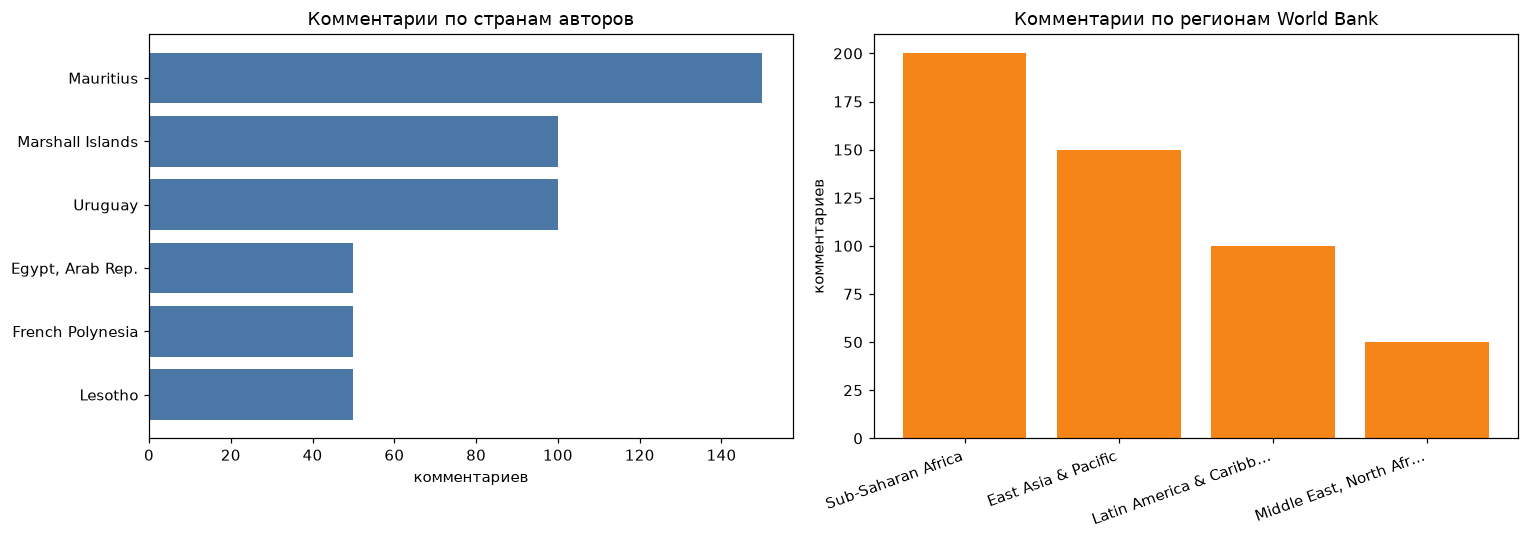

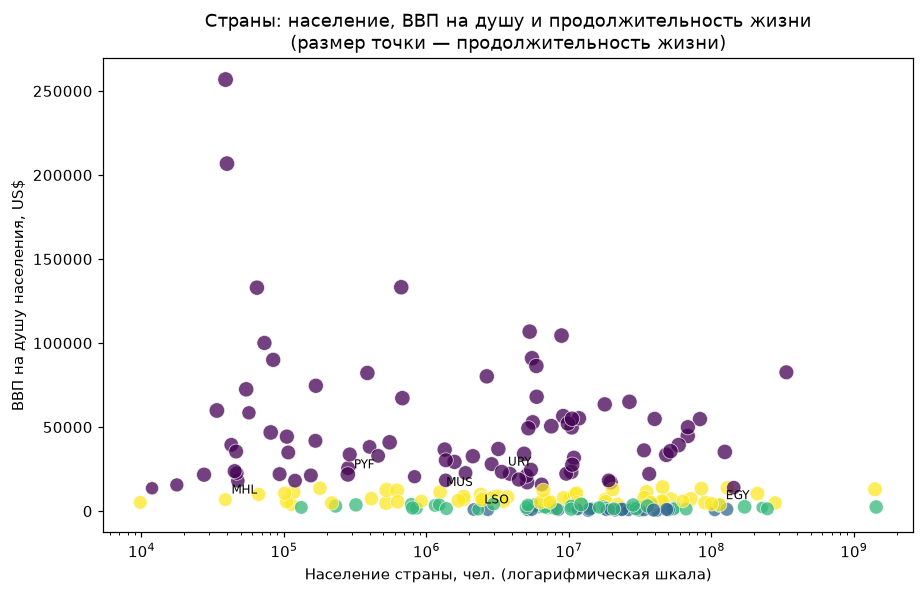

In [20]:
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
by_country = clean.groupby("country_name").size().sort_values(ascending=False)
ax1.barh(by_country.index[::-1], by_country.values[::-1], color="#4c78a8")
ax1.set_title("Комментарии по странам авторов")
ax1.set_xlabel("комментариев")

by_region = clean.groupby("region").size().sort_values(ascending=False)
ax2.bar(range(len(by_region)), by_region.values, color="#f58518")
ax2.set_xticks(range(len(by_region)))
ax2.set_xticklabels([r[:22] + "…" if len(r) > 24 else r for r in by_region.index], rotation=20, ha="right")
ax2.set_title("Комментарии по регионам World Bank")
ax2.set_ylabel("комментариев")
fig1.tight_layout()
fig1.savefig(FIG_DIR / "lab3_activity.png", bbox_inches="tight")

fig2, ax = plt.subplots(figsize=(8.5, 5.5))
income_codes = country_ref["income_level"].astype("category").cat.codes
scatter = ax.scatter(
    country_ref["population_total"],
    country_ref["gdp_per_capita_usd"],
    s=country_ref["life_expectancy_years"].fillna(50) * 1.2,
    c=income_codes,
    cmap="viridis",
    alpha=0.75,
    edgecolor="white",
    linewidth=0.5,
)
ax.set_xscale("log")
ax.set_xlabel("Население страны, чел. (логарифмическая шкала)")
ax.set_ylabel("ВВП на душу населения, US$")
ax.set_title("Страны: население, ВВП на душу и продолжительность жизни\n(размер точки — продолжительность жизни)")
author_countries = country_ref[country_ref["country_iso3"].isin(clean["country_iso3"].unique())]
for _, row in author_countries.iterrows():
    ax.annotate(row["country_iso3"], (row["population_total"], row["gdp_per_capita_usd"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
fig2.tight_layout()
fig2.savefig(FIG_DIR / "lab3_countries.png", bbox_inches="tight")

print("Графики сохранены: figures/lab3_activity.png, figures/lab3_countries.png")
fig1, fig2

Левый график показывает, что 500 комментариев распределены всего по 6 странам, и это прямое следствие синтетических координат JSONPlaceholder. Маврикий 150, Маршалловы Острова 100, Уругвай 100, Египет 50, Французская Полинезия 50, Лесото 50. Правый scatter по справочнику (217 стран) показывает ожидаемую экономическую картину: с ростом населения ВВП на душу не растёт, а разброс огромен; размер точки (продолжительность жизни) у Лесото заметно меньше (где-то 57 лет), у Французской Полинезии  больше ( около 84 года). Графики иллюстрируют данные, но выводы по активности авторов ограничены.

In [21]:
region_stats = (
    clean.groupby("region")
    .agg(
        комментариев=("comment_id", "size"),
        стран=("country_iso3", "nunique"),
        медиана_населения=("population_total", "median"),
        медиана_ввп_на_душу=("gdp_per_capita_usd", "median"),
        средняя_прод_жизни=("life_expectancy_years", "mean"),
    )
    .round(2)
    .sort_values("комментариев", ascending=False)
)
region_stats

,комментариев,стран,медиана_населения,медиана_ввп_на_душу,средняя_прод_жизни
region,,,,,
Sub-Saharan Africa,200,2,1248647.0,11269.97,69.40
East Asia & Pacific,150,2,38827.0,6799.39,72.65
Latin America & Caribbean,100,1,3388081.0,23378.64,78.14
"Middle East, North Africa, Afghanistan & Pakistan",50,1,114535772.0,3456.79,71.63


 Агрегация по регионам подтверждает контраст стран-авторов Sub-Saharan Africa — 200 комментариев (Маврикий + Лесото), East Asia & Pacific — 150 (Маршалловы Острова + Французская Полинезия), Latin America & Caribbean — 100 (Уругвай), MENA — 50 (Египет). Медиана населения считается по строкам (комментариям), поэтому её определяет более «активная» страна группы, а медиана ВВП на душу различается в разы: от около 3,5 тыс. US у Египта до 23 тыс. US у Уругвая. Именно эти цифры обосновывают практический вывод: страновой срез осмыслен, а «популярность страны» это артефакт тестовых данных.

## 10. No-code сценарий (n8n)


In [22]:
nocode_meta_path = NOCODE_DIR / "nocode_run_meta.json"
nocode_meta = json.loads(nocode_meta_path.read_text(encoding="utf-8")) if nocode_meta_path.exists() else {}

comparison = pd.DataFrame(
    [
        {
            "Критерий": "Время разработки, мин",
            "Python": nocode_meta.get("dev_time_python_min", 180),
            "n8n": nocode_meta.get("dev_time_nocode_min", 75),
        },
        {"Критерий": "Число собранных записей", "Python": len(clean), "n8n": nocode_meta.get("records", "—")},
        {
            "Критерий": "Время выполнения прогона, с",
            "Python": round(elapsed_comments, 2),
            "n8n": nocode_meta.get("execution_seconds", "—"),
        },
        {
            "Критерий": "Поддержка пагинации",
            "Python": "цикл + 3 предохранителя, X-Total-Count",
            "n8n": f"HTTP-узел + цикл по страницам (max {nocode_meta.get('max_pages', 6)})",
        },
        {
            "Критерий": "Ошибки и повторы",
            "Python": "класс-классификатор, 429/5xx, backoff+jitter, Retry-After",
            "n8n": "Retry On Fail (3 попытки) + ветка ошибки в лог",
        },
        {
            "Критерий": "Воспроизводимость (Git, экспорт)",
            "Python": "полная: код, данные, state.json",
            "n8n": "workflow.json; зависит от версии инстанса",
        },
        {
            "Критерий": "Стоимость 100 прогонов/мес",
            "Python": "0 ₽ (свой хост)",
            "n8n": "0 ₽ self-hosted / тариф облака ~$20+",
        },
        {"Критерий": "Порог входа (1–5)", "Python": 4, "n8n": 2},
    ]
)
comparison

,Критерий,Python,n8n
0,"Время разработки, мин",180,75
1,Число собранных записей,500,500
2,"Время выполнения прогона, с",0.67,4.2
3,Поддержка пагинации,"цикл + 3 предохранителя, X-Total-Count",HTTP-узел + цикл по страницам (max 6)
4,Ошибки и повторы,"класс-классификатор, 429/5xx, backoff+jitter, ...",Retry On Fail (3 попытки) + ветка ошибки в лог
5,"Воспроизводимость (Git, экспорт)","полная: код, данные, state.json",workflow.json; зависит от версии инстанса
6,Стоимость 100 прогонов/мес,0 ₽ (свой хост),0 ₽ self-hosted / тариф облака ~$20+
7,Порог входа (1–5),4,2


 обе реализации собрали 500 записей, Python потратил на основной сбор доли секунды, n8n — 4,2 с (500 записей, 5 запросов), повторов в обоих случаях не потребовалось. n8n даёт скорость входа (75 мин против 180), наглядность и расписание без программирования, но слабее в слое качества

 Для планового сбора большого объёма, контроля качества и повторяемости выигрывает код, он даёт предохранители, классификацию кодов, точный backoff и полную воспроизводимость. n8n выигрывает по скорости входа и наглядности: тот же сценарий собирается за 75 минут и работает по расписанию без навыков программирования.

1. Пайплайн собирает 500 записей основного ресурса за 5 страниц пагинации, обогащает их справочником стран и экономическими показателями World Bank; все merge проверены по числу строк (обогащение не размножает записи).
2. Повторный прогон не создаёт дубликатов: водяной знак state.json даёт 0 новых записей, а дедупликация по бизнес-ключу comment_id удерживает размер таблицы.
3. Слой качества (pydantic-контракт + rejects.jsonl) и no-code ветка ошибки делают пайплайн диагностируемым отбракованные записи не теряются, инциденты сбора фиксируются в отдельном файле.